In [58]:
import numpy as np
import matplotlib.pyplot as plt

**1) DISCRETIZACIÓN:** Con la ecuación de Poisson:
\begin{align*}
    \frac{\partial ^2 \Phi}{\partial r^2} + \frac{1}{r} \frac{\partial \Phi}{\partial r} + \frac{\partial ^2 \Phi}{\partial z^2} = 4\pi G \rho_0 \exp{\left(-\frac{r}{r_0}\right)} \exp{\left(-\frac{z^2}{2h^2}\right)}
\end{align*}
Con una región rectangular $R_{\text{max}} \times Z_{\text{max}}$ y un número de pasos $N_r \times N_z = 50 \times 20$:
\begin{align*}
    \Delta r = \frac{R_{\text{max}}}{N_r}  \quad \Delta z = \frac{Z_{\text{max}}}{N_z} 
\end{align*}
Aproximando con diferencias centradas:
\begin{align*}
    &\frac{\partial \Phi}{\partial r} = \frac{\Phi_{i+1,j} - \Phi_{i-1,j}}{2\Delta r} \quad,\quad \frac{\partial^2\Phi}{\partial r^2} = \frac{\Phi_{i+1,j} - 2\Phi_{i,j} + \Phi_{i-1,j}}{(\Delta r)^2} \\[7pt]
    &\frac{\partial^2\Phi}{\partial z^2} = \frac{\Phi_{i,j+1} - 2\Phi_{i,j} + \Phi_{i,j-1}}{(\Delta z)^2}
\end{align*}

Reemplazando en la ecuación de Poisson:
\begin{align*}
    \frac{\Phi_{i+1,j} - 2\Phi_{i,j} + \Phi_{i-1,j}}{(\Delta r)^2} + \frac{1}{r}\frac{\Phi_{i+1,j} - \Phi_{i-1,j}}{2\Delta r} + \frac{\Phi_{i,j+1} - 2\Phi_{i,j} + \Phi_{i,j-1}}{(\Delta z)^2} &= 4\pi G \rho_0 \exp{\left(-\frac{r}{r_0}\right)} \exp{\left(-\frac{z^2}{2h^2}\right)}
\end{align*}
Agrupando términos:
\begin{align*}
    &A \Phi_{i+1, j} + B \Phi_{i-1, j} + C (\Phi_{i, j+1} + \Phi_{i, j-1}) - D \Phi_{i, j} = S_{i, j}
\end{align*}
Con $S_{i, j} = 4\pi G \rho_0 e^{-r_i / r_0} e^{-z_j ^2 / 2h^2}$ y:
\begin{align*}
    A = \frac{1}{\Delta r ^2} + \frac{1}{2r_i \Delta r}, \quad B = \frac{1}{\Delta r ^2} - \frac{1}{2r_i \Delta r}, \quad C = \frac{1}{\Delta z ^2}, \quad D = 2\left(\frac{1}{\Delta r ^2} + \frac{1}{\Delta z ^2}\right)
\end{align*}
Separando entre los métodos Gauss-Seidel y SOR.
\begin{align*}
    &\text{Gauss-Seidel:} \quad \Phi_{i, j} = \frac{A \Phi_{i+1, j} + B \Phi_{i-1, j} + C (\Phi_{i, j+1} + \Phi_{i, j-1}) - S_{i, j}}{D} \\[10pt]
    &\text{SOR:} \quad \Phi_{i, j} ^{\text{relajado}} = \lambda \Phi_{i, j} ^{\text{nuevo}} + (1 - \lambda) \Phi_{i, j} ^{\text{prev}}, \quad 1 < \lambda < 2
\end{align*}

In [59]:
# =================================================
# 2) IMPLEMENTACIÓN:
# =================================================

# ------ CONSTANTES ------
UA = 1.496e11 # m/UA
r0 = 3*UA # m
h = 0.5*UA # m
rho0 = 1e-9 * 1e3 # kg / m^3
G = 6.674e-11

# ------ PARÁMETROS DE MALLA Y SOLUCIÓN ------

Nr, Nz = 50, 20
lam = 1.5
Rmax, Zmax = 10*UA, 2*UA # m

dr, dz = Rmax/Nr, 2*Zmax/Nz # En este caso se usará una malla desde -Zmax hasta +Zmax (2Zmax), pero con el mismo Nz
r = np.linspace(0, Rmax, Nr+1)
z = np.linspace(-Zmax, Zmax, Nz+1)
R, Z = np.meshgrid(r, z, indexing='ij')

# ------ COEFICIENTES ------

S = 4*np.pi * G * rho0 * np.exp(-R/r0) * np.exp(-Z**2 / (2 * h**2))
ri = r[1:-1]
A = 1/dr**2 + 1/(2 * ri * dr)
B = 1/dr**2 - 1/(2 * ri * dr)
C = 1/dz**2
D = 2 * (1/dr**2 + 1/dz**2)

# ------ SOLUCIONADOR ------

def sor(lam, tol=1e-3, max_iter=int(1e6)):
    Phi = np.zeros((Nr + 1, Nz + 1))
    for it in range(1, max_iter + 1):
        max_eps = 0.0
        for i in range(1, Nr):
            for j in range(1, Nz):
                Phi_new = (A[i - 1] * Phi[i + 1, j] + B[i - 1] * Phi[i - 1, j] + C * (Phi[i, j + 1] + Phi[i, j - 1]) - S[i, j]) / D
                Phi_relaxed = (1 - lam) * Phi[i, j] + lam * Phi_new

                max_eps = max(max_eps, abs(Phi_relaxed - Phi[i, j]))
                Phi[i, j] = Phi_relaxed
        if max_eps/np.max(np.abs(Phi)) < tol:
            return Phi, it
    raise RuntimeError('El método no convergió.')

Phi_gs, it_gs   = sor(1.0) # El método Gauss-Seidel es el mismo método SOR con un valor de lambda = 1
Phi_sor, it_sor = sor(1.5) # Trabajamos con SOR de lambda = 1.5
print(f'Gauss-Seidel: {it_gs} iteraciones. SOR (1.5): {it_sor} iteraciones.')

Gauss-Seidel: 170 iteraciones. SOR (1.5): 83 iteraciones.


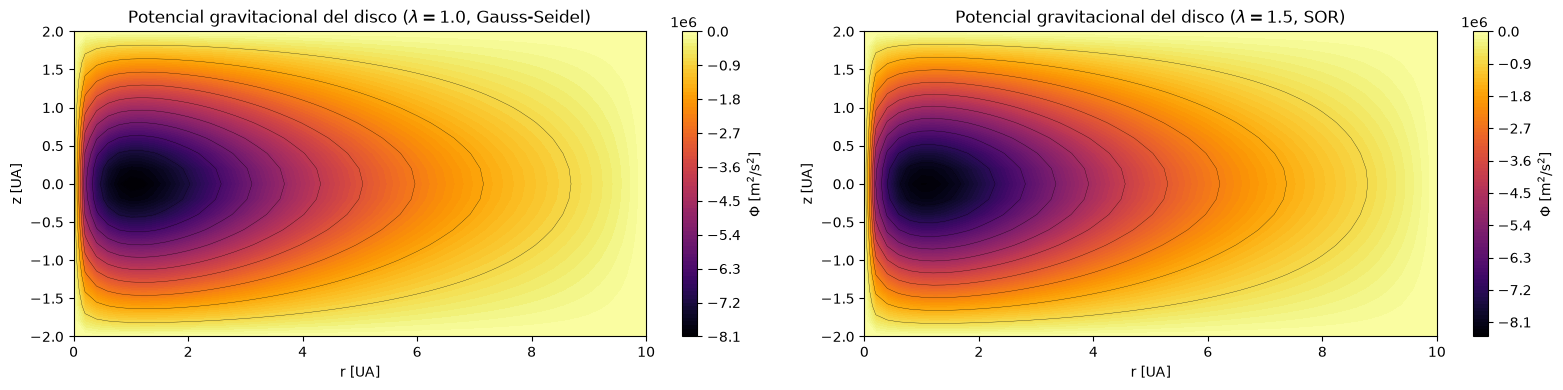

In [60]:
# =================================================
# 3) GRAFICACIÓN:
# =================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4))
cf1 = ax1.contourf(R/UA, Z/UA, Phi_gs, 100, cmap='inferno')
ax1.contour(R/UA, Z/UA, Phi_gs, 10, colors='k', linewidths=0.2, linestyles='-')
plt.colorbar(cf1, label=r'$\Phi$ [m$^2$/s$^2$]')
ax1.set_xlabel('r [UA]'); ax1.set_ylabel('z [UA]'); ax1.set_title(r'Potencial gravitacional del disco ($\lambda = 1.0$, Gauss-Seidel)')

cf2 = ax2.contourf(R/UA, Z/UA, Phi_sor, 100, cmap='inferno')
ax2.contour(R/UA, Z/UA, Phi_sor, 10, colors='k', linewidths=0.2, linestyles='-')
plt.colorbar(cf2, label=r'$\Phi$ [m$^2$/s$^2$]')
ax2.set_xlabel('r [UA]'); ax2.set_ylabel('z [UA]'); ax2.set_title(r'Potencial gravitacional del disco ($\lambda = 1.5$, SOR)')


plt.tight_layout()
plt.show()

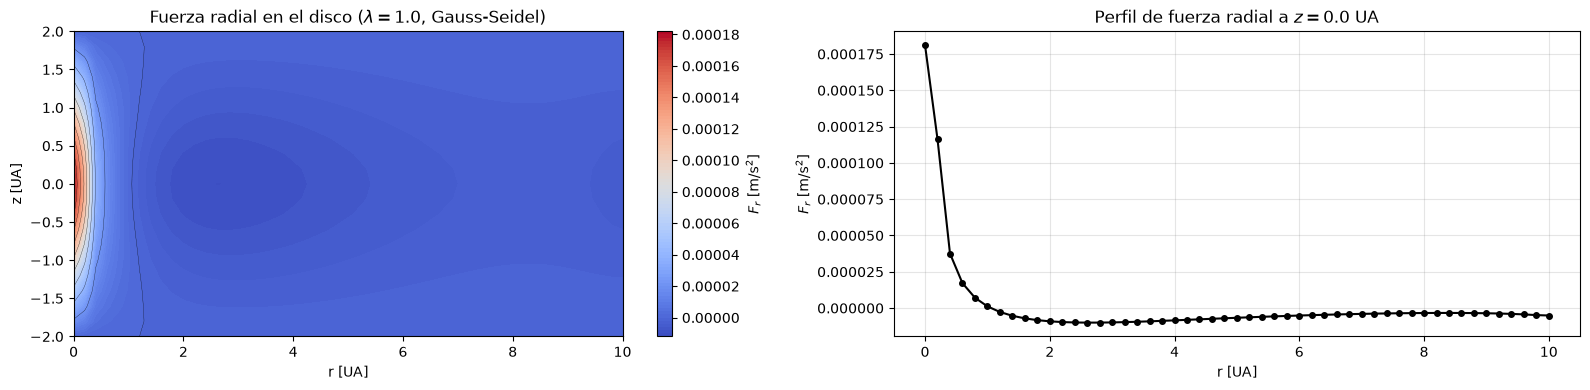

In [61]:
# =================================================
# 4) FUERZA GRAVITACIONAL RADIAL:
# =================================================

Fr_gs = -1*np.gradient(Phi_gs, dr, axis=0)

# Altura sobre la cual se graficará Fr
z_plane = Nz//2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4))

cf = ax1.contourf(R/UA, Z/UA, Fr_gs, 100, cmap='coolwarm')
ax1.contour(R/UA, Z/UA, Fr_gs, 10, colors='k', linewidths=0.2, linestyles='-')
plt.colorbar(cf, label=r'$F_r$ [m/s$^2$]')
ax1.set_xlabel('r [UA]'); ax1.set_ylabel('z [UA]'); ax1.set_title(r'Fuerza radial en el disco ($\lambda = 1.0$, Gauss-Seidel)')

ax2.plot(r/UA, Fr_gs[:, z_plane], 'o-', color='k', ms=4)
ax2.set_xlabel('r [UA]'); ax2.set_ylabel(r'$F_r$ [m/s$^2$]'); ax2.set_title(rf'Perfil de fuerza radial a $z = {z[z_plane]/UA:.1f}$ UA')
ax2.grid(color='gray', alpha=0.2)

plt.tight_layout()
plt.show()

Masa M del disco: M = 2.005e+29 kg


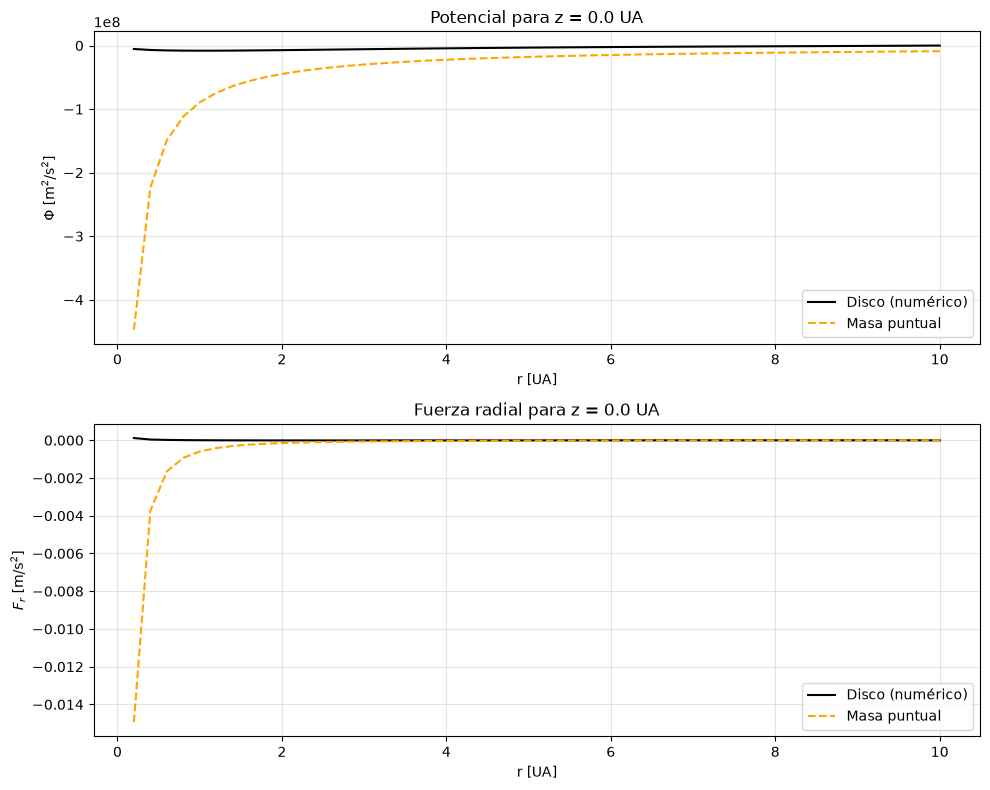

In [62]:
# =================================================
# 5) COMPARACIÓN:
# =================================================

# Para calcular el potencial según r y z es necesario calcular la masa M según rho(r, z), integrando:

rho = rho0 * np.exp(-R/r0) * np.exp(-Z**2 / (2 * h**2))

M = np.trapezoid(np.trapezoid(rho * 2 * np.pi * R, z, axis=1), r)
print(f'Masa M del disco: M = {M:.3e} kg')

with np.errstate(divide='ignore'):
    Phi_analytic = -G*M/np.sqrt(R**2 + Z**2)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

ax1.plot(r[1:]/UA, Phi_gs[1:, z_plane], color='k', label='Disco (numérico)')
ax1.plot(r[1:]/UA, Phi_analytic[1:, z_plane],  '--', color='orange', label='Masa puntual')
ax1.set_xlabel('r [UA]'); ax1.set_ylabel(r'$\Phi$ [m$^2$/s$^2$]'); ax1.set_title(f'Potencial para z = {z[z_plane]/UA:.1f} UA')
ax1.grid(color='gray', alpha=0.2)
ax1.legend()

# Para una comparación de la fuerza radial:

with np.errstate(divide='ignore', invalid='ignore'):
    Fr_analytic = -G * M * R / (R**2 + Z**2)**(3/2)

ax2.plot(r[1:]/UA, Fr_gs[1:, z_plane], color='k', label='Disco (numérico)')
ax2.plot(r[1:]/UA, Fr_analytic[1:, z_plane],  '--', color='orange', label='Masa puntual')
ax2.set_xlabel('r [UA]'); ax2.set_ylabel(r'$F_r$ [m/s$^2$]'); ax2.set_title(f'Fuerza radial para z = {z[z_plane]/UA:.1f} UA')
ax2.grid(color='gray', alpha=0.2)
ax2.legend()

plt.tight_layout()
plt.show()


Se observa que el potencial del disco es mucho menos profundo que el caso puntual, mientras que la fuerza gravitatoria radial numérica resulta de menor magnitud comparado con el caso kepleriano esperado, sobre todo cerca al centro del disco (bajas distancias $r$).

Aparte de los picos obtenidos en los extremos de la grilla debido a la condición de Dirichlet de $\Phi = 0$, la fuerza gravitatoria radial es, como se esperaría, negativa (y por lo tanto atractiva).

Debido a la distribución de masa variable según nos alejamos, el perfil se aleja del caso puntual expuesto. Por otro lado, la condición de Dirichlet en este dominio finito apantalla el campo. Sin embargo se observa que ambos mantienen un comportamiento parecido a grandes distancias del disco, con el potencial negativo que tiende a cero.

Aparte de esto, se comprueba lo esperado respecto a los métodos de Gauss-Seidel y SOR de $\lambda = 1.5$, siendo que este último resultó convergente con una menor cantidad de iteraciones necesarias (83 para SOR y 170 para Gauss-Seidel) utilizando la misma tolerancia, gracias a la relajación de los términos utilizados.
